Today's topics:

* how a large language model writes text
* generative AI as a data source
* joining two tables with `pd.merge`
* comparing two sources with percent differences and parity plots

# Germanium on silicon

Today we will ask a chatbot for property data and check its answers against a reference table.

<img src="https://upload.wikimedia.org/wikipedia/commons/thumb/b/bd/Molecular-beam_epitaxy_412_RIBER_system_at_LAAS-CNRS.jpg/960px-Molecular-beam_epitaxy_412_RIBER_system_at_LAAS-CNRS.jpg" alt="A molecular-beam epitaxy system, a stainless steel vacuum chamber with many ports, flanges, cooling lines and cables, standing in a cleanroom laboratory" width=480/>

*Photo by QGravelier, [CC BY-SA 4.0](https://creativecommons.org/licenses/by-sa/4.0), [via Wikimedia Commons](https://commons.wikimedia.org/wiki/File:Molecular-beam_epitaxy_412_RIBER_system_at_LAAS-CNRS.jpg).*

Above: A [molecular-beam epitaxy](https://en.wikipedia.org/wiki/Molecular-beam_epitaxy) system, like the one from our critical thickness example.
Systems like this grow thin crystal layers, one atomic layer at a time.

Germanium layers grown on silicon wafers are used in fast transistors and in light detectors.
Germanium atoms sit a little farther apart than silicon atoms.

Remember the lattice mismatch from our critical thickness example?

$$f = \frac{a_f - a_s}{a_s}$$

To get $f$ for germanium on silicon we need both lattice constants.

Could we just ask a chatbot for them?

## Let's ask

Here is the request we will type in:

> I need some property data for a materials class project. For each of these elements, give me the crystal structure at room temperature, the lattice constant a in angstroms, and the thermal conductivity at room temperature in W/(m K): Fe, Cu, Al, Ni, Ti, W, Si, Ge, Mo, Sn, C, Mn. Give a source for each row. If you do not know a value, leave it blank. Answer as CSV with the columns symbol, structure, lattice_constant, thermal_conductivity, source.

The reply we get in class may differ from the one below.
The rest of today uses the saved reply below.

## The reply we saved

This is the reply from Claude Haiku 5.5 on November 15, 2026:

```
These values are from memory, not checked against a source. Verify them before they go into the project.

symbol,structure,lattice_constant,thermal_conductivity,source
Fe,BCC (alpha),2.866,80.4,CRC Handbook of Chemistry and Physics (from memory; verify)
Cu,FCC,3.615,401,CRC Handbook of Chemistry and Physics (from memory; verify)
Al,FCC,4.050,237,CRC Handbook of Chemistry and Physics (from memory; verify)
Ni,FCC,3.524,90.9,CRC Handbook of Chemistry and Physics (from memory; verify)
Ti,HCP (alpha),2.951,21.9,CRC Handbook of Chemistry and Physics (from memory; verify); a only, c = 4.686 A
W,BCC,3.165,173,CRC Handbook of Chemistry and Physics (from memory; verify)
Si,Diamond cubic,5.431,149,CRC Handbook of Chemistry and Physics (from memory; verify)
Ge,Diamond cubic,5.658,60.2,CRC Handbook of Chemistry and Physics (from memory; verify)
Mo,BCC,3.147,138,CRC Handbook of Chemistry and Physics (from memory; verify)
Sn,Tetragonal (white tin),5.832,66.6,CRC Handbook of Chemistry and Physics (from memory; verify); a only, c = 3.182 A
C,Hexagonal (graphite),2.464,,Lattice from CRC Handbook (from memory; verify); conductivity left blank because graphite is strongly anisotropic (no single value)
Mn,Cubic (alpha-Mn),8.913,7.81,CRC Handbook of Chemistry and Physics (from memory; verify)

Notes: lattice constants are a only, at about 298 K. Thermal conductivity is at about 300 K. Source strings are general citations, not page-level references. Sources are quoted per row for the CRC Handbook; no page numbers were checked.
```

Every row cites the CRC Handbook, but the reply says it did not check the handbook.
The citation names where such numbers are usually printed.
It does not tell us where these came from.

Many chatbots give a confident citation with no warning at all.

Let's copy the numbers into a table.
We leave out the source column and use `np.nan` for the blank:

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
llm = pd.DataFrame({
    'symbol': ['Fe', 'Cu', 'Al', 'Ni', 'Ti', 'W', 'Si', 'Ge', 'Mo', 'Sn', 'C', 'Mn'],
    'structure': ['BCC (alpha)', 'FCC', 'FCC', 'FCC', 'HCP (alpha)', 'BCC',
                  'Diamond cubic', 'Diamond cubic', 'BCC', 'Tetragonal (white tin)',
                  'Hexagonal (graphite)', 'Cubic (alpha-Mn)'],
    'lattice_constant': [2.866, 3.615, 4.050, 3.524, 2.951, 3.165,
                         5.431, 5.658, 3.147, 5.832, 2.464, 8.913],  # Å
    'thermal_conductivity': [80.4, 401, 237, 90.9, 21.9, 173,
                             149, 60.2, 138, 66.6, np.nan, 7.81],  # W/(m K)
})
display(llm)

,symbol,structure,lattice_constant,thermal_conductivity
0,Fe,BCC (alpha),2.866,80.40
1,Cu,FCC,3.615,401.00
2,Al,FCC,4.050,237.00
3,Ni,FCC,3.524,90.90
4,Ti,HCP (alpha),2.951,21.90
5,W,BCC,3.165,173.00
6,Si,Diamond cubic,5.431,149.00
7,Ge,Diamond cubic,5.658,60.20
8,Mo,BCC,3.147,138.00
9,Sn,Tetragonal (white tin),5.832,66.60


# How a language model writes

Chatbots like ChatGPT, Copilot, and Claude run on a **large language model** (LLM).

The model splits text into **tokens**: words, pieces of words, digits, and punctuation.
Given the text so far, it gives a probability to every possible next token.
Then it picks one, adds it, and repeats.

Many chatbots pick at random, weighted by the probabilities.
That is why the same request can give a different reply.

A value like 5.431 for silicon appears in many texts.
The model often writes it correctly.
But nothing in this process looks the number up.

Some chatbots can also search the web.
Check whether yours did.

# Generative AI and data ethics

Last time we asked where data come from and what we may do with them.
Generative AI adds three questions:

* **Before we ask:** what we type into a public chatbot goes to a company's servers.
  Keep out data under a nondisclosure agreement or export control.
  Keep out unpublished data we are not allowed to share.
  The syllabus has the course policy.
* **When we use the reply:** a generated number is not a measurement.
  Reporting it as a measurement is fabrication.
  Do not claim we checked a source when we did not.
  Keep AI estimates labeled and separate from measurements.
* **When we report:** we say which tool we used and what we did with its output.

So before we use these numbers, let's check them.

# Comparing two tables

## A reference table

For a reference, let's use the element table from `mendeleev`, a Python package we used early in the semester.

Its [documentation](https://mendeleev.readthedocs.io/en/stable/data.html) gives the units of these columns, but not where the values came from.
It is fine for a quick check, but it is not a primary source.

In [3]:
elements = pd.read_csv('https://raw.githubusercontent.com/wfreinhart/matse219/main/datasets/mendeleev_elements.csv')
print(elements.shape)  # rows, columns

(118, 43)


We only need a few of its 43 columns:

In [4]:
ref = elements[['symbol', 'lattice_structure', 'lattice_constant']]
display(ref.head())

,symbol,lattice_structure,lattice_constant
0,H,HEX,3.75
1,He,HEX,3.57
2,Li,BCC,3.49
3,Be,HEX,2.29
4,B,TET,8.73


The reference is in order of atomic number.
It starts with hydrogen.
Our chatbot table starts with iron.

The rows don't line up.
We can't just compare them by position.
We need to match rows by the element symbol.

## Joining tables with `merge`

`pd.merge` joins two tables using a column they share, called the **key**.

For each row of the left table, it finds the row in the right table with the same key and puts the two side by side.
Here each symbol appears once in each table.

`how='left'` keeps every row of the left table.
If the right table has no match, the new columns get `NaN`.

A `NaN` after a merge can also be a blank that was already in one of the tables.

Both tables have a `lattice_constant` column.
`merge` keeps both copies and adds `_x` and `_y` to their names unless we choose other endings with `suffixes`:

In [5]:
compared = pd.merge(llm, ref, on='symbol', how='left', suffixes=('_llm', '_ref'))
display(compared)

,symbol,structure,lattice_constant_llm,thermal_conductivity,lattice_structure,lattice_constant_ref
0,Fe,BCC (alpha),2.866,80.40,BCC,2.87
1,Cu,FCC,3.615,401.00,FCC,3.61
2,Al,FCC,4.050,237.00,FCC,4.05
3,Ni,FCC,3.524,90.90,FCC,3.52
4,Ti,HCP (alpha),2.951,21.90,HEX,2.95
5,W,BCC,3.165,173.00,BCC,3.16
6,Si,Diamond cubic,5.431,149.00,DIA,5.43
7,Ge,Diamond cubic,5.658,60.20,DIA,5.66
8,Mo,BCC,3.147,138.00,BCC,3.15
9,Sn,Tetragonal (white tin),5.832,66.60,TET,5.82


Now each row has the chatbot's value and the reference value side by side.

Look at the two structure columns.
The tables use different words: `HCP (alpha)` against `HEX`, `Diamond cubic` against `DIA`.
We have to read those by eye.

### [Check your understanding]

Let's compare the thermal conductivities.

1. Merge `llm_k` and `ref_k` below with `how='left'` and the suffixes `'_llm'` and `'_ref'`.
2. Print the rows where the reference value is missing.

For which elements can we not check the chatbot against this table?
Which element did the chatbot itself leave blank?

In [6]:
llm_k = llm[['symbol', 'thermal_conductivity']]
ref_k = elements[['symbol', 'thermal_conductivity']]

# Percent difference

Let's measure how far apart the two lattice constants are, as a percent of the reference:

In [7]:
diff = compared['lattice_constant_llm'] - compared['lattice_constant_ref']
compared['diff_percent'] = 100 * diff / compared['lattice_constant_ref']
display(compared[['symbol', 'lattice_constant_llm', 'lattice_constant_ref', 'diff_percent']])

,symbol,lattice_constant_llm,lattice_constant_ref,diff_percent
0,Fe,2.866,2.87,-0.139373
1,Cu,3.615,3.61,0.138504
2,Al,4.050,4.05,0.000000
3,Ni,3.524,3.52,0.113636
4,Ti,2.951,2.95,0.033898
5,W,3.165,3.16,0.158228
6,Si,5.431,5.43,0.018416
7,Ge,5.658,5.66,-0.035336
8,Mo,3.147,3.15,-0.095238
9,Sn,5.832,5.82,0.206186


Every element except carbon is within 0.3%.
The reference keeps only two decimal places.
Rounding can contribute to these differences.

Carbon's chatbot value is 31% lower than the reference!

## A parity plot

If the two sources agreed perfectly, every point would sit on the line $y = x$.

This is called a **parity plot**:

Text(0, 0.5, 'chatbot lattice constant (Å)')

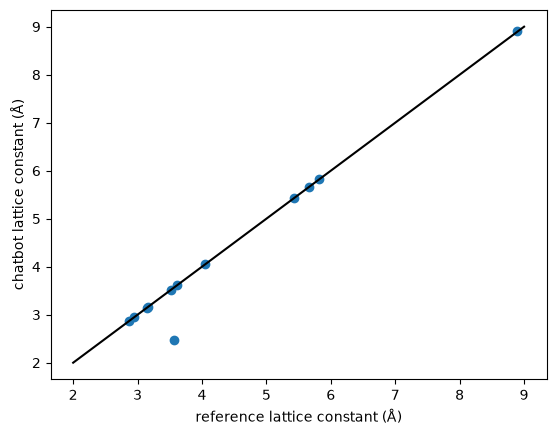

In [8]:
fig, ax = plt.subplots()
ax.scatter(compared['lattice_constant_ref'], compared['lattice_constant_llm'])
ax.plot([2, 9], [2, 9], 'k-')  # the line y = x
ax.set_xlabel('reference lattice constant (Å)')
ax.set_ylabel('chatbot lattice constant (Å)')

One point sits well below the line.
That's carbon.

## Is the chatbot wrong about carbon?

Let's print the carbon row:

In [9]:
display(compared[compared['symbol'] == 'C'])

,symbol,structure,lattice_constant_llm,thermal_conductivity,lattice_structure,lattice_constant_ref,diff_percent
10,C,Hexagonal (graphite),2.464,NaN,DIA,3.57,-30.980392


The chatbot gave graphite with $a = 2.464$ angstroms ([AIST crystal database](https://unit.aist.go.jp/mmri/ja/organization/db-nomura/common/struc-coord/C%28Graphite%29-c.html)).
The reference gave diamond with $a = 3.57$ angstroms ([Hom, Kiszenik, and Post, 1975](https://doi.org/10.1107/S0021889875010965)).

In graphite, $a$ is a spacing within one flat sheet of atoms.
In diamond, $a$ is the edge of the cubic cell.

Both numbers are right for their own crystal.
Graphite and diamond are two different materials made of carbon.

So a large percent difference is a reason to look closer.
We only call a value wrong after we know both sources describe the same material under the same conditions.

### [Check your understanding]

Let's finish the thermal conductivity comparison.

1. Using your merged table from the first check, add a percent difference column for thermal conductivity.
2. Print the rows where the absolute percent difference is larger than 1%.
   `np.abs` gives the absolute value.

If the result is an empty table, is that good news?
Which rows have a missing value on either side?
Which chatbot values would you check in another source before using them?

# Back to germanium on silicon

Let's compute the mismatch from the chatbot's numbers and from a measurement.

`.iloc[0]` takes the single value out of a one-row selection:

In [10]:
si = compared[compared['symbol'] == 'Si']
ge = compared[compared['symbol'] == 'Ge']

a_si = si['lattice_constant_llm'].iloc[0]
a_ge = ge['lattice_constant_llm'].iloc[0]
print('chatbot:', (a_ge - a_si) / a_si)

print('measured:', (5.657820 - 5.430941) / 5.430941)  # Hom et al. (1975), at 25 °C

chatbot: 0.04179709077517958
measured: 0.04177526509678531


The measured line uses lattice constants from X-ray diffraction, corrected to 25 °C ([Hom, Kiszenik, and Post, 1975](https://doi.org/10.1107/S0021889875010965)).

Both give 0.0418, or 4.2%.
The chatbot was right here, but the number we report is the measured one, because we can cite it.

That is almost 50 times the germanium on gallium arsenide mismatch (0.09%) from our critical thickness example.
This larger mismatch limits the thickness of germanium layers on silicon that grow without dislocations.

## Writing it up

Here is how we could report what we did:

> **Data note.** Lattice constants for 12 elements were generated by Claude Haiku 5.5 on November 15, 2026, from the prompt above, and compared with the `mendeleev` element table.
> All agree within 0.3% except carbon, where the two sources describe different crystals (graphite and diamond).
> Thermal conductivities for Mo and Mn could not be checked against this table; it has no value for them.
> The mismatch of germanium on silicon, 4.2%, uses the measured lattice constants of Hom et al. (1975).

# Summary

* A large language model writes one token at a time, from probabilities learned from text.
* A generated number is not a measurement; check it against a source before reporting it.
* Say which AI tool you used and what you did with its output.
* `pd.merge(left, right, on='key', how='left')` joins two tables by a shared column.
* `suffixes` names the columns that appear in both tables.
* A parity plot compares two sources against the line $y = x$.

## Further reading

* pandas, [Merge, join, concatenate and compare](https://pandas.pydata.org/docs/user_guide/merging.html)
* mendeleev, [Data](https://mendeleev.readthedocs.io/en/stable/data.html), the units and descriptions of each property
* Photo credit: molecular-beam epitaxy system, QGravelier, [CC BY-SA 4.0](https://creativecommons.org/licenses/by-sa/4.0), [Wikimedia Commons](https://commons.wikimedia.org/wiki/File:Molecular-beam_epitaxy_412_RIBER_system_at_LAAS-CNRS.jpg)